# # Praktikum 2 — CNN untuk CIFAR-10
# Modul memakai `keras.datasets.cifar10.load_data()` (unduh ~170 MB dari cs.toronto.edu).
# Di lingkungan ini server tersebut tidak bisa diunduh utuh (koneksi reset / sangat lambat),
# jadi dipakai **subset CIFAR-10 asli** yang ditarik dari mirror Hugging Face
# (`uoft-cs/cifar10`) dan disimpan di `data/cifar10_subset.npz`.
# Ukuran subset: 20.000 citra latih + 1.967 citra uji, resolusi asli 32x32, 10 kelas.
# Arsitektur dan alur pelatihan tetap sama dengan modul (3 layer Conv).

In [1]:
import os
__file__ = os.path.abspath("conv_cifar10.ipynb")

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
import tensorflow as tf

tf.random.set_seed(42); np.random.seed(42)

BASE = Path(__file__).resolve().parent.parent
OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(parents=True, exist_ok=True)
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

In [2]:
d = np.load(BASE / "data" / "cifar10_subset.npz")
x_train, y_train = d["x_train"], d["y_train"]
x_test, y_test = d["x_test"], d["y_test"]
print("train:", x_train.shape, "test:", x_test.shape)
print("distribusi kelas latih:", np.bincount(y_train, minlength=10))

train: (20000, 32, 32, 3) test: (1967, 32, 32, 3)
distribusi kelas latih: [2000 2000 2000 2000 2000 2000 2000 2000 2000 2000]


# ## 1. Plot 25 sampel citra

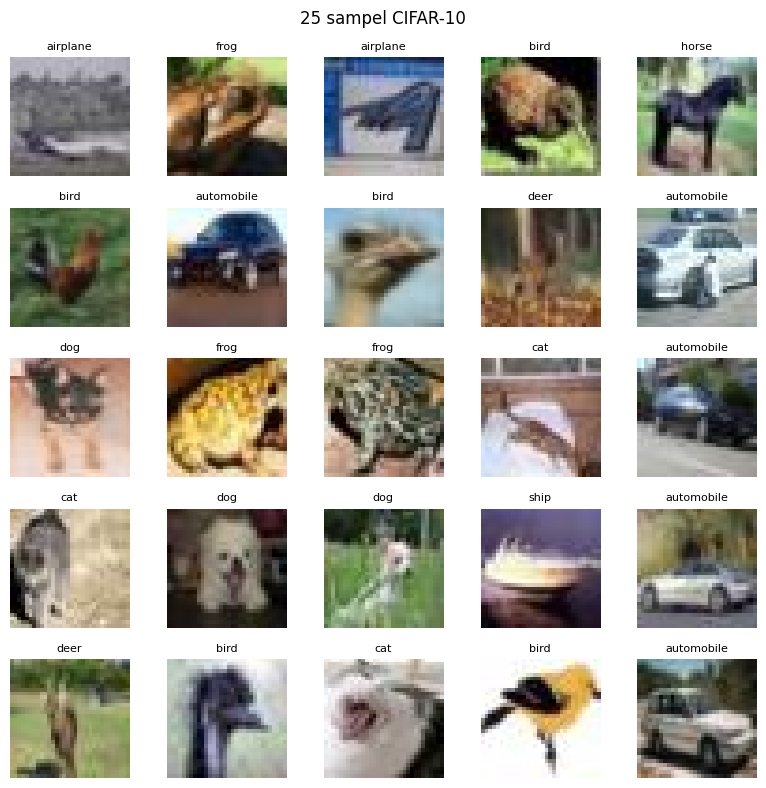

In [3]:
fig, axes = plt.subplots(5, 5, figsize=(8, 8))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(x_train[i]); ax.set_title(CLASSES[y_train[i]], fontsize=8); ax.axis("off")
plt.suptitle("25 sampel CIFAR-10"); plt.tight_layout()
plt.savefig(OUT / "sampel_25.png", dpi=110); plt.show()

# ## 2. Preprocessing + arsitektur (3 Conv)

In [4]:
xt = x_train.astype("float32") / 255.0
xe = x_test.astype("float32") / 255.0
yt = to_categorical(y_train, 10)
ye = to_categorical(y_test, 10)

model = Sequential([
    Conv2D(32, (3, 3), activation="relu", input_shape=(32, 32, 3)),
    MaxPooling2D(2, 2),
    Conv2D(32, (3, 3), activation="relu"),
    MaxPooling2D(2, 2),
    Conv2D(64, (3, 3), activation="relu"),
    Flatten(),
    Dense(128, activation="relu"),
    Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 conv2d (Conv2D)             (None, 30, 30, 32)        896       


 max_pooling2d (MaxPooling2  (None, 15, 15, 32)        0         


 D)                                                              


... (7 outputs left out)

Total params: 161130 (629.41 KB)


Trainable params: 161130 (629.41 KB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


# ## 3. Pelatihan (8 epoch, 20.000 citra latih, CPU)

In [5]:
# Modul: epochs=10, validation_data=(test_images, test_labels)
history = model.fit(xt, yt, batch_size=64, epochs=10,
                    validation_data=(xe, ye), verbose=2)

Epoch 1/10


313/313 - 6s - loss: 1.7932 - accuracy: 0.3440 - val_loss: 1.6186 - val_accuracy: 0.3986 - 6s/epoch - 18ms/step


Epoch 2/10


313/313 - 4s - loss: 1.4567 - accuracy: 0.4728 - val_loss: 1.4225 - val_accuracy: 0.4881 - 4s/epoch - 14ms/step


Epoch 3/10


313/313 - 4s - loss: 1.3427 - accuracy: 0.5208 - val_loss: 1.3330 - val_accuracy: 0.5226 - 4s/epoch - 14ms/step


... (10 outputs left out)

Epoch 9/10


313/313 - 5s - loss: 0.9451 - accuracy: 0.6698 - val_loss: 1.0983 - val_accuracy: 0.6065 - 5s/epoch - 16ms/step


Epoch 10/10


313/313 - 5s - loss: 0.8947 - accuracy: 0.6842 - val_loss: 1.0818 - val_accuracy: 0.6274 - 5s/epoch - 16ms/step


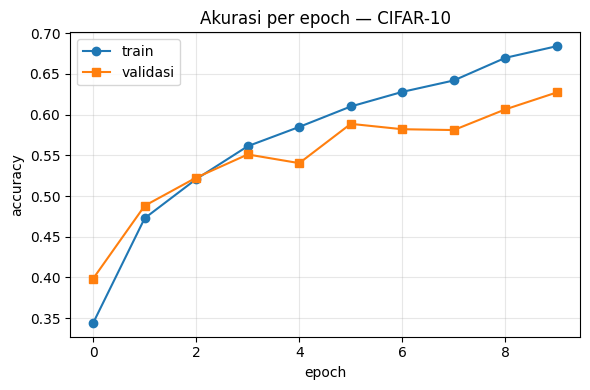

In [6]:
plt.figure(figsize=(6, 4))
plt.plot(history.history["accuracy"], marker="o", label="train")
plt.plot(history.history["val_accuracy"], marker="s", label="validasi")
plt.title("Akurasi per epoch — CIFAR-10"); plt.xlabel("epoch"); plt.ylabel("accuracy")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig(OUT / "history_accuracy.png", dpi=110); plt.show()

# ## 4. Evaluasi data uji

In [7]:
test_loss, test_acc = model.evaluate(xe, ye, verbose=0)
print(f"test_loss={test_loss:.4f}  test_acc={test_acc:.4f}")
np.savetxt(OUT / "test_acc.csv", np.array([[test_loss, test_acc]]), delimiter=",", header="loss,acc", comments="")

test_loss=1.0818  test_acc=0.6274
